<a href="https://colab.research.google.com/github/24ai097-sujipriya/deep-learning-assignments/blob/main/dl(cat2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cryptocurrency Price Prediction using LSTM



In [27]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt


df = pd.read_csv('/content/coin_Aave.csv')


df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)


df = df.ffill().bfill()


subset_size = 2000
data_subset = df.tail(subset_size).copy()


scaler = MinMaxScaler(feature_range=(0, 1))
scaled_close = scaler.fit_transform(data_subset[['Close']].values)

print(f"Original dataset shape: {df.shape}")
print(f"Subset dataset shape: {data_subset.shape}")

Original dataset shape: (275, 10)
Subset dataset shape: (275, 10)


In [28]:
def create_sequences(data, window_size=7):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:(i + window_size)])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

WINDOW_SIZE = 7
X, y = create_sequences(scaled_close, WINDOW_SIZE)
print(f"Input shape (X): {X.shape} (samples, time steps, features)")
print(f"Target shape (y): {y.shape} (samples, targets)")

Input shape (X): (268, 7, 1) (samples, time steps, features)
Target shape (y): (268, 1) (samples, targets)


In [29]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

def build_lstm_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        LSTM(50, return_sequences=True),
        Dropout(0.2),
        LSTM(50, return_sequences=False),
        Dropout(0.2),
        Dense(25),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

model = build_lstm_model((WINDOW_SIZE, 1))
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_12 (LSTM)                  │ (None, 7, 50)          │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 7, 50)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_13 (LSTM)                  │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

split_idx = int(len(X) * 0.8)

X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

history = model.fit(
    X_train, y_train,
    epochs=25,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

predictions_scaled = model.predict(X_test)

predictions = scaler.inverse_transform(predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test)

mae = mean_absolute_error(y_test_actual, predictions)
rmse = np.sqrt(mean_squared_error(y_test_actual, predictions))

print(f"\nEvaluation Metrics on Test Set:")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

Epoch 1/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - loss: 0.1694 - val_loss: 0.0925
Epoch 2/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0469 - val_loss: 0.0200
Epoch 3/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0305 - val_loss: 0.0155
Epoch 4/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0167 - val_loss: 0.0140
Epoch 5/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0135 - val_loss: 0.0104
Epoch 6/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0078 - val_loss: 0.0175
Epoch 7/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0073 - val_loss: 0.0119
Epoch 8/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0058 - val_loss: 0.0125
Epoch 9/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0067 - val_loss: 0.0152
Epoch 10/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0063 - val_loss: 0.0110
Epoch 11/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0058 - val_loss: 0.0120
Epoch 12/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0060 - val_loss: 0.0123


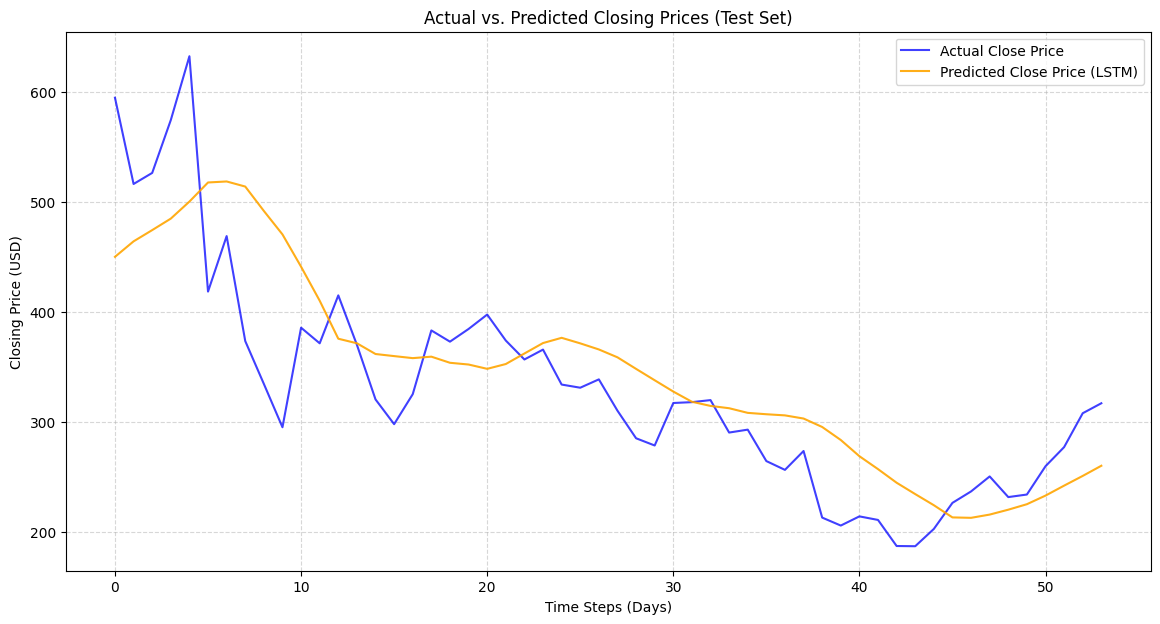

In [31]:

plt.figure(figsize=(14, 7))
plt.plot(y_test_actual, label='Actual Close Price', color='blue', alpha=0.75)
plt.plot(predictions, label='Predicted Close Price (LSTM)', color='orange', alpha=0.9)
plt.title('Actual vs. Predicted Closing Prices (Test Set)')
plt.xlabel('Time Steps (Days)')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()